# 02 - Radar to language (first end-to-end pass, nuScenes mini)

Goal of this notebook: close the loop from radar to words. A frame's radar goes in, someone asks a question about the scene, and a language model answers. This first pass runs on the small mini dataset to prove the whole chain works; it is **not** expected to give good answers yet.

**Terms, in plain words**

- **nuScenes-QA**: about 460,000 questions about nuScenes scenes, e.g. *"Are any cars visible?"* (answer: yes / no), *"How many pedestrians are to the front left of it?"* (answer: a number). We use only the 5,916 questions that belong to mini keyframes: 3,384 for training and 2,532 for testing (the QA dataset's own "val" split).
- **Radar words (visual tokens)**: a language model reads *tokens* (word pieces). We cut the radar map into 16 x 16 = 256 patches and turn each patch into one token, so the model can "read" the radar in front of the question.
- **Projector**: a small network that turns the radar network's 64 numbers per patch into the 896-number format the language model uses for its tokens. This is the "translator" between radar and language, and it is trained here.
- **LoRA**: instead of retraining all 500 million numbers of the language model, we add small extra layers (2.2 million numbers) and train only those. Cheap and less prone to overfitting.
- **Exact-match accuracy**: an answer counts only if it is identical to the true answer ("3" is right, "three" is wrong).
- **Most-common-answer baseline**: answer every question with the most frequent training answer for its question type (no radar, no language model). This is the bar to beat.
- **Blind model**: the same language model trained the same way but with the radar tokens removed. It shows what can be learned from the question text alone.
- **Wrong-frame control**: give the trained radar model the radar of a *different, random keyframe*. If the model really reads the radar, its accuracy should drop clearly. If it does not drop, the model is not using the radar's content.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import FancyBboxPatch

ROOT = Path(r"D:\radar-bev-llm")
radar = json.load(open(ROOT / "outputs" / "qa_radar.json"))               # trained WITH radar tokens
blind = json.load(open(ROOT / "outputs" / "qa_blind.json"))               # same model, radar tokens removed
wrong = json.load(open(ROOT / "outputs" / "qa_radar_wrong_frame.json"))   # the radar model given another keyframe's radar
split = json.load(open(ROOT / "outputs" / "qa_split_by_radar_seen.json"))  # same scores, split by whether the RADAR network had trained on the scene
val_questions = json.load(open(ROOT / "cache" / "nuscenes_qa_mini_mirror_val.json", encoding="utf-8"))

n_val = len(val_questions)
print(f"{n_val} validation questions")
print(f"most-common-answer baseline : {radar['majority_baseline']:.3f}")
print(f"blind model (no radar)      : {blind['val_acc']:.3f}")
print(f"radar model, WRONG frame    : {np.mean(wrong['shuffled']):.3f}   (3 random shuffles: {', '.join(f'{x:.3f}' for x in wrong['shuffled'])})")
print(f"radar model, correct frame  : {radar['val_acc']:.3f}")

2532 validation questions
most-common-answer baseline : 0.407
blind model (no radar)      : 0.502
radar model, WRONG frame    : 0.520   (3 random shuffles: 0.519, 0.519, 0.522)
radar model, correct frame  : 0.531


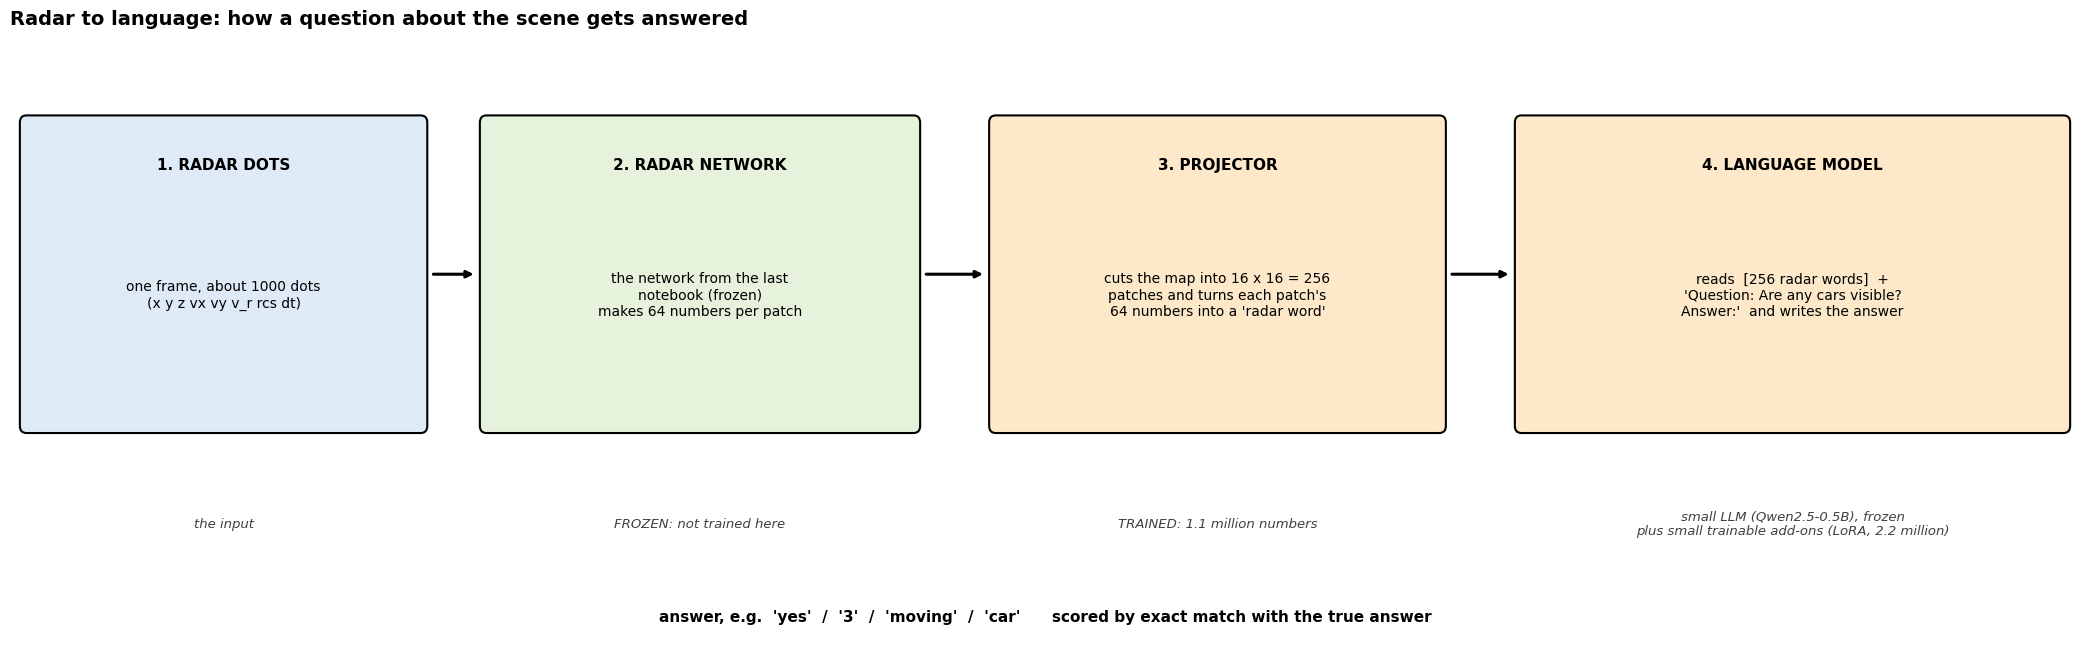

In [2]:
fig, ax = plt.subplots(figsize=(21, 6.6))
ax.set_xlim(0, 126)
ax.set_ylim(0, 34)
ax.axis("off")
steps = [
    (1, 24, "1. RADAR DOTS", "one frame, about 1000 dots\n(x y z vx vy v_r rcs dt)", "the input", "#dfeaf7"),
    (29, 26, "2. RADAR NETWORK", "the network from the last\nnotebook (frozen)\nmakes 64 numbers per patch", "FROZEN: not trained here", "#e6f2dc"),
    (60, 27, "3. PROJECTOR", "cuts the map into 16 x 16 = 256\npatches and turns each patch's\n64 numbers into a 'radar word'", "TRAINED: 1.1 million numbers", "#fde9c9"),
    (92, 33, "4. LANGUAGE MODEL", "reads  [256 radar words]  +\n'Question: Are any cars visible?\nAnswer:'  and writes the answer", "small LLM (Qwen2.5-0.5B), frozen\nplus small trainable add-ons (LoRA, 2.2 million)", "#fde9c9"),
]
for x0, w, title, body, note, colour in steps:
    ax.add_patch(FancyBboxPatch((x0, 12), w, 17, boxstyle="round,pad=0.4", fc=colour, ec="k", lw=1.5))
    ax.text(x0 + w / 2, 26.6, title, ha="center", va="center", fontsize=11, fontweight="bold")
    ax.text(x0 + w / 2, 19.3, body, ha="center", va="center", fontsize=10)
    ax.text(x0 + w / 2, 6.5, note, ha="center", va="center", fontsize=9.5, style="italic", color="0.25")
for x0, x1 in ((25.6, 28.4), (55.6, 59.4), (87.6, 91.4)):
    ax.annotate("", xy=(x1, 20.5), xytext=(x0, 20.5), arrowprops=dict(arrowstyle="-|>", lw=2.2))
ax.text(63, 1.0, "answer, e.g.  'yes'  /  '3'  /  'moving'  /  'car'      scored by exact match with the true answer",
        ha="center", fontsize=11, fontweight="bold")
ax.set_title("Radar to language: how a question about the scene gets answered", fontsize=14, fontweight="bold", loc="left")
plt.tight_layout()
plt.show()

### The setup

- Language model: **Qwen2.5-0.5B-Instruct** (496 million numbers), a small model chosen for a fast first pass. The plan is to swap in LLaMA-3-8B later.
- Radar features: from the radar network trained with mirror augmentation (previous notebook), cached for every mini keyframe by `code/radar/make_bev_cache.py`.
- Training: 5 epochs, batch size 8, on the 3,384 training questions (`code/radar/train_qa.py`). The radar model ran on the RTX 3080 and the blind model on the RTX 3060 Ti, about 12 minutes each.

### Results, explained on the figure

**Left:** accuracy on the 2,532 test questions, split into two groups. This split matters: the radar network was trained on some mini scenes, and about 57% of the test questions come from those scenes (1,446 questions), so for them the radar features are "cleaner" than they would be on new data. Only the 43% from **brand-new scenes** (1,086 questions) are an honest test.

**Right:** the same accuracy by question type.

**What we can and cannot say**

- The full chain works: radar -> features -> language model -> written answers -> scored. That was the goal of this pass.
- Both trained models beat the most-common-answer baseline (0.41 -> about 0.50). But the **blind** model gets most of that: the language model learns which answers are typical for each kind of question (for example "yes" is common for existence questions, and existence questions are 80% right even without radar).
- On brand-new scenes the model with the correct radar scores 0.489, the same model with the *wrong frame's* radar 0.483, the blind model 0.474. The differences are about 0.01 and the measurement noise is about 0.015, so **we cannot show that the model uses the radar yet.**
- Counting questions are hard for every model (about 0.2).

**Why this is expected on mini, and what to try next**

- Very little data: 3,384 training questions from 6 scenes.
- The radar network was trained on the same 8 scenes, so the features on training scenes are unrealistically clean, and the projector may learn from patterns that do not exist on new scenes.
- Only a single training run, so small differences are within noise.
- Next: more data (trainval has about 460,000 questions and 700 training scenes), and then a bigger language model. If the wrong-frame control still shows no drop after that, we change how radar enters the model, for example by giving it the detected objects (positions, speeds) as explicit tokens.

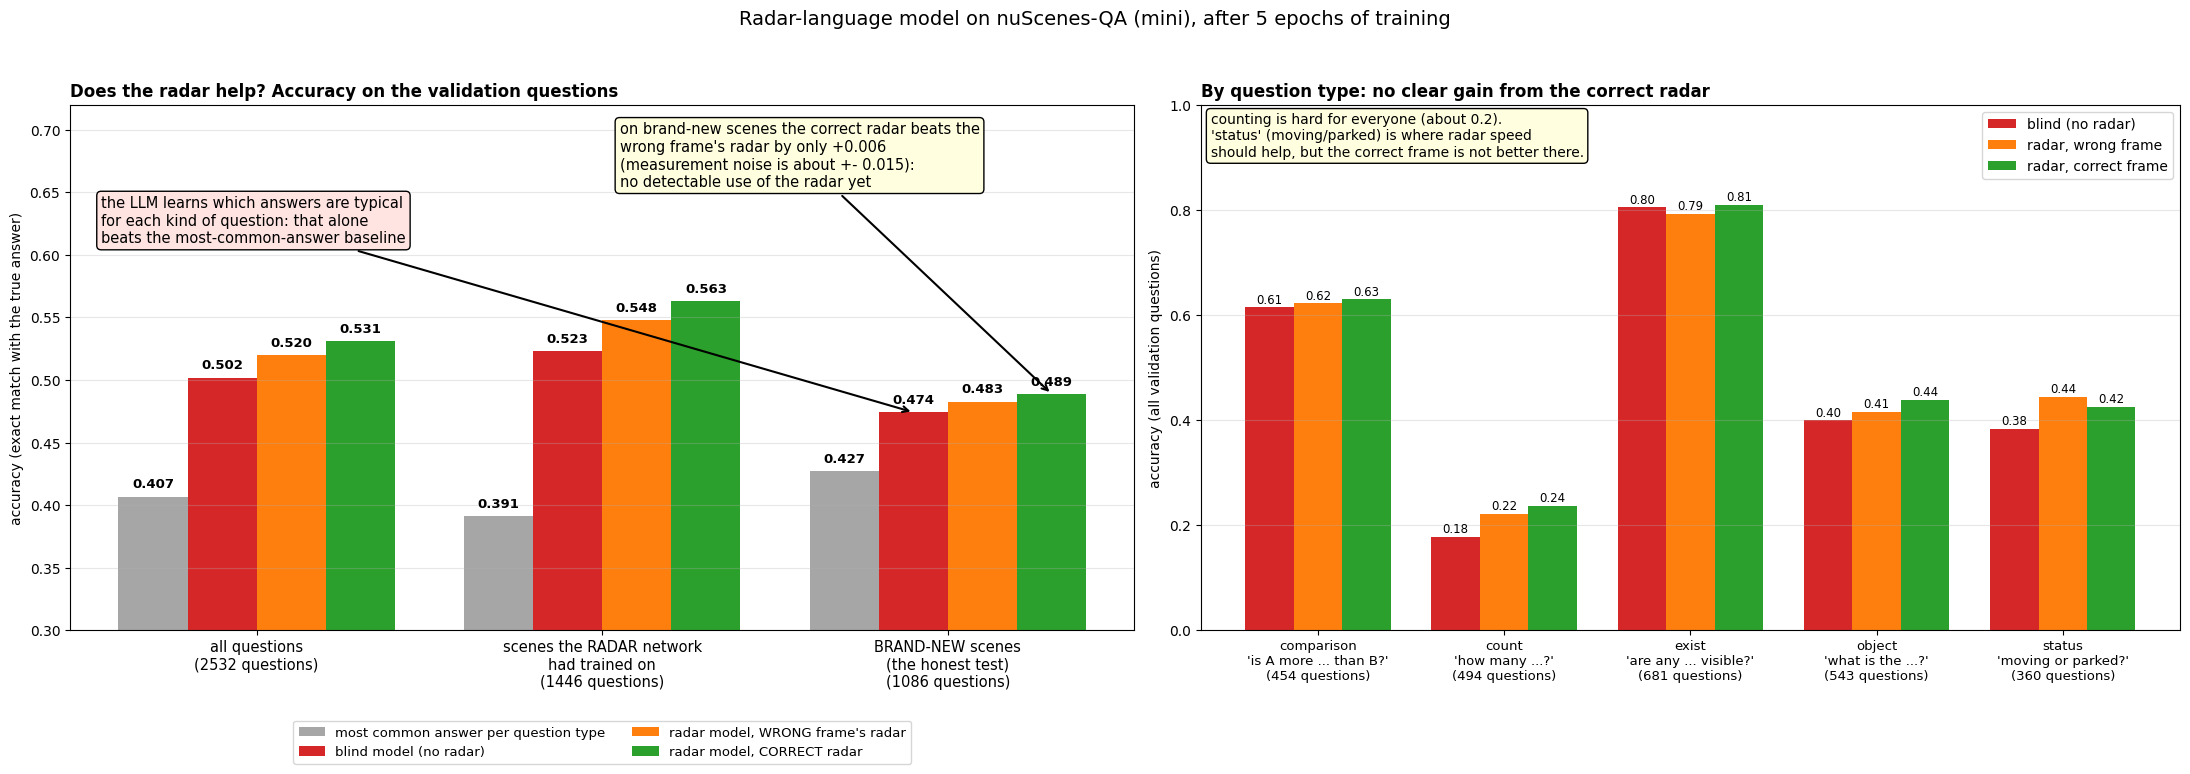

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(22, 8), gridspec_kw=dict(width_ratios=[1.25, 1.15]))

# ---- left: overall accuracy, split by whether the radar network had ever trained on the scene ----
ax = axes[0]
groups = [("all_", "all questions", split["all"]),
          ("seen", "scenes the RADAR network\nhad trained on", split["seen_by_radar_net"]),
          ("new", "BRAND-NEW scenes\n(the honest test)", split["unseen_by_radar_net"])]
series = [("most common answer per question type", "majority", "0.65"), ("blind model (no radar)", "blind", "tab:red"),
          ("radar model, WRONG frame's radar", "wrong", "tab:orange"), ("radar model, CORRECT radar", "radar", "tab:green")]
w = 0.2
for k, (name, key, col) in enumerate(series):
    xs = np.arange(3) + (k - 1.5) * w
    vals = [g[2][key] for g in groups]
    ax.bar(xs, vals, w, color=col, label=name)
    for x_, v_ in zip(xs, vals):
        ax.text(x_, v_ + 0.007, f"{v_:.3f}", ha="center", fontsize=9.5, fontweight="bold", rotation=90 if False else 0)
ax.set_xticks(range(3))
ax.set_xticklabels([f"{t}\n({g['n']} questions)" for _, t, g in groups], fontsize=10.5)
ax.set_ylim(0.3, 0.72)
ax.set_ylabel("accuracy (exact match with the true answer)")
new = split["unseen_by_radar_net"]
ax.annotate(f"on brand-new scenes the correct radar beats the\nwrong frame's radar by only +{new['radar'] - new['wrong']:.3f}\n(measurement noise is about +- {new['noise']:.3f}):\nno detectable use of the radar yet",
            xy=(2 + 1.5 * w, new["radar"]), xytext=(1.05, 0.655), fontsize=10.5,
            bbox=dict(boxstyle="round", fc="lightyellow", ec="k"), arrowprops=dict(arrowstyle="->", lw=1.5))
ax.annotate("the LLM learns which answers are typical\nfor each kind of question: that alone\nbeats the most-common-answer baseline",
            xy=(2 - 0.5 * w, new["blind"]), xytext=(-0.45, 0.61), fontsize=10.5,
            bbox=dict(boxstyle="round", fc="mistyrose", ec="k"), arrowprops=dict(arrowstyle="->", lw=1.5))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, fontsize=9.5)
ax.set_title("Does the radar help? Accuracy on the validation questions", fontsize=12, fontweight="bold", loc="left")
ax.grid(alpha=0.3, axis="y")

# ---- right: by question type (all validation questions) ----
ax = axes[1]
types = sorted(radar["per_type"])
label = {"comparison": "comparison\n'is A more ... than B?'", "count": "count\n'how many ...?'", "exist": "exist\n'are any ... visible?'",
         "object": "object\n'what is the ...?'", "status": "status\n'moving or parked?'"}
w = 0.26
for k, (name, get, col) in enumerate((("blind (no radar)", lambda t: blind["per_type"][t], "tab:red"),
                                      ("radar, wrong frame", lambda t: wrong["per_type"][t][2], "tab:orange"),
                                      ("radar, correct frame", lambda t: radar["per_type"][t], "tab:green"))):
    v = [get(t) for t in types]
    ax.bar(np.arange(len(types)) + (k - 1) * w, v, w, color=col, label=name)
    for x_, v_ in zip(np.arange(len(types)) + (k - 1) * w, v):
        ax.text(x_, v_ + 0.008, f"{v_:.2f}", ha="center", fontsize=8.5)
ax.set_xticks(range(len(types)))
ax.set_xticklabels([label[t] + f"\n({radar['n_per_type'][t]} questions)" for t in types], fontsize=9.5)
ax.set_ylim(0, 1.0)
ax.set_ylabel("accuracy (all validation questions)")
ax.set_title("By question type: no clear gain from the correct radar", fontsize=12, fontweight="bold", loc="left")
ax.legend(loc="upper right", fontsize=10)
ax.grid(alpha=0.3, axis="y")
ax.text(0.01, 0.985, "counting is hard for everyone (about 0.2).\n'status' (moving/parked) is where radar speed\nshould help, but the correct frame is not better there.",
        transform=ax.transAxes, va="top", fontsize=10, bbox=dict(boxstyle="round", fc="lightyellow", ec="k"))

fig.suptitle("Radar-language model on nuScenes-QA (mini), after 5 epochs of training", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

### A few test questions: what each model answered

`ok` = matches the true answer, `x` = wrong. The models often agree with each other, which is what you would expect if both mostly rely on the question text.

In [4]:
# A few validation questions with the true answer and what each model said (first 200 questions are stored in the results)
shown, per_type_count = [], {}
for q, truth, p_radar, p_blind in zip(val_questions, radar["answers"], radar["preds"], blind["preds"]):
    t = q["template_type"]
    if per_type_count.get(t, 0) < 3:
        per_type_count[t] = per_type_count.get(t, 0) + 1
        shown.append((t, q["question"], truth.lower(), p_radar, p_blind))

print(f"{'type':11s} {'true answer':12s} {'radar model':16s} {'blind model':16s} question")
print("-" * 130)
for t, question, truth, pr, pb in shown:
    print(f"{t:11s} {truth:12s} {pr[:14] + (' ok' if pr == truth else ' x'):16s} {pb[:14] + (' ok' if pb == truth else ' x'):16s} {question[:70]}")

type        true answer  radar model      blind model      question
----------------------------------------------------------------------------------------------------------------------------------
count       5            10 x             9 x              There is a not standing pedestrian; what number of things are to the f
count       7            10 x             5 x              There is a not standing pedestrian; what number of things are to the b
exist       yes          yes ok           yes ok           Are any cars visible?
exist       no           no ok            no ok            Are there any moving cars to the back left of me?
exist       yes          yes ok           yes ok           Are there any other cars that in the same status as the car to the fro
object      car          car ok           car ok           There is a parked thing; what is it?
count       7            10 x             8 x              What number of cars are there?
object      car          bus x     